In [1]:
%matplotlib inline
import numpy as np
import lightkurve as lk
import matplotlib.pyplot as plt

/opt/anaconda3/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [32]:
period = 0.65356
observations = 0.02041667 
window_points = period / observations
print(window_points)

32.01109681451481


In [34]:
search

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,Kepler Quarter 02,2009,Kepler,1800,kplr012557548,0.0
1,Kepler Quarter 03,2009,Kepler,1800,kplr012557548,0.0
2,Kepler Quarter 04,2010,Kepler,1800,kplr012557548,0.0
3,Kepler Quarter 05,2010,Kepler,1800,kplr012557548,0.0
4,Kepler Quarter 06,2010,Kepler,1800,kplr012557548,0.0


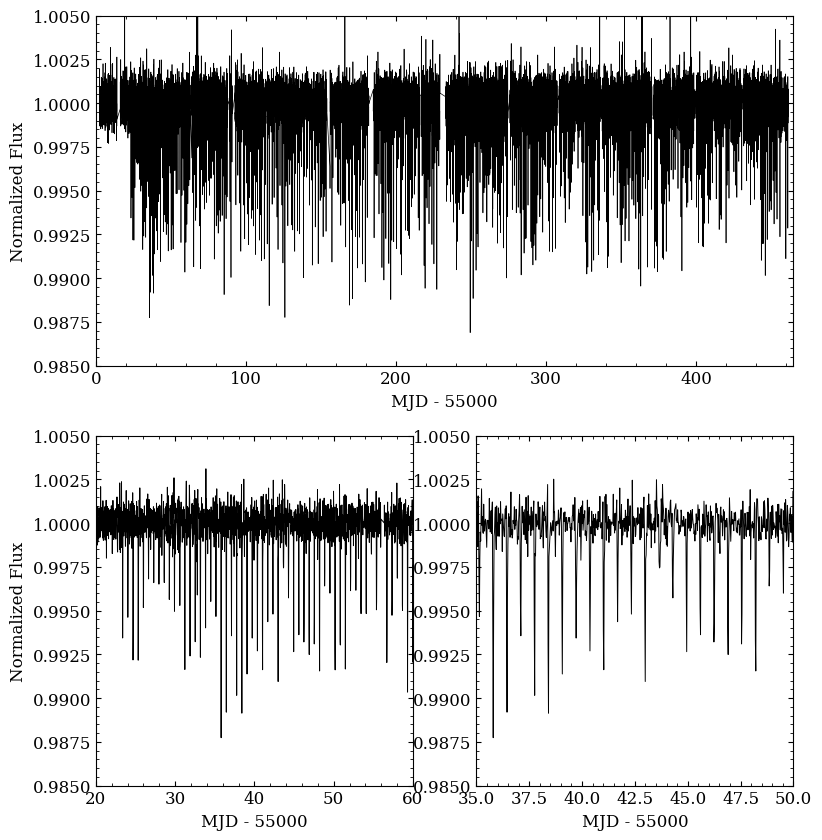

In [152]:

import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk

search = lk.search_lightcurve("KIC 12557548", mission="Kepler", author="Kepler",
                              exptime="long", quarter=[2, 3, 4, 5, 6])
lcs = search.download_all(flux_column="sap_flux")

lc = lcs.stitch().remove_nans()

time = lc.time.mjd - 55000


detrended_flux = lc.flatten(window_length=31).flux.value
#try sigma clipping with .remove_outliers

plt.figure(figsize=(9, 10))


plt.subplot(2, 1, 1)
plt.plot(time, detrended_flux, color = "black", linestyle = "-", linewidth=0.5)
plt.xlim(0, 465)
plt.ylim(0.985, 1.005)
plt.xlabel("MJD - 55000")
plt.ylabel("Normalized Flux")



plt.subplot(2, 2, 3)
plt.plot(time, detrended_flux, color = "black", linestyle = "-", linewidth=0.7)
plt.xlim(20, 60)
plt.ylim(0.985, 1.005)
plt.xlabel("MJD - 55000")
plt.ylabel("Normalized Flux")



plt.subplot(2, 2, 4)
plt.plot(time, detrended_flux, color = "black", linestyle = "-", linewidth=0.7)
plt.xlim(35, 50)
plt.ylim(0.985, 1.005)
plt.xlabel("MJD - 55000")


plt.show()

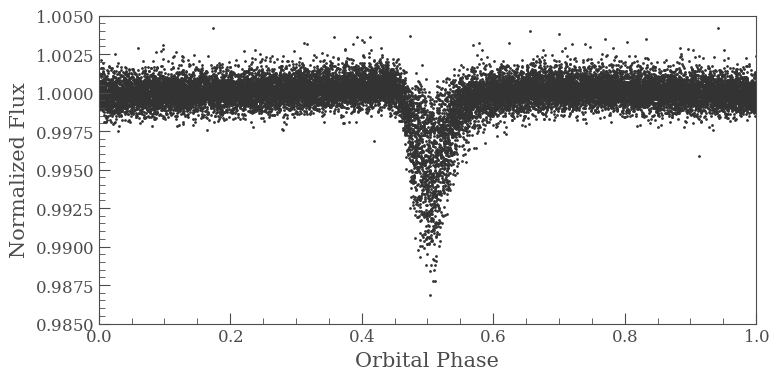

In [154]:
lc_detrended = lk.LightCurve(time=lc.time, flux=detrended_flux)

folded = lc_detrended.fold(period=0.65356, epoch_time=567.324, normalize_phase=True, epoch_phase=0.5, wrap_phase=1)
binned = folded.bin(bins=96)
    
folded.scatter()
plt.xlim(0,1)
plt.ylim(0.985,1.005)
plt.xlabel("Orbital Phase")
plt.ylabel("Normalized Flux")

plt.show()

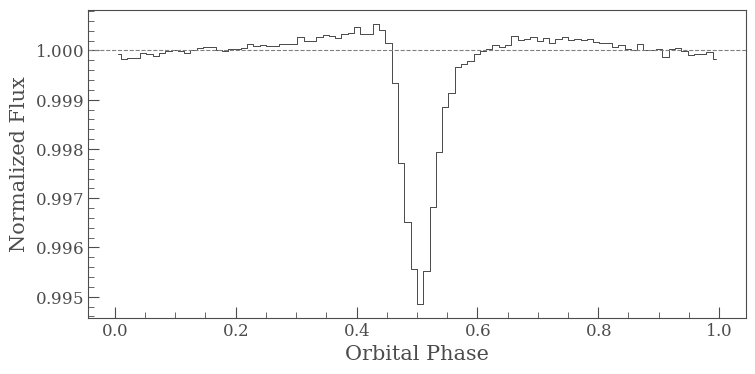

In [156]:
binned.plot(color="black", drawstyle="steps-mid")
plt.xlabel("Orbital Phase")
plt.ylabel("Normalized Flux")
plt.axhline(y=1, color="gray", linestyle="--", linewidth=0.8)
plt.show()